# BÀI KIỂM TRA 2: XÂY DỰNG, HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH
**Học phần:** Học máy
**Đề tài:** Dự báo điện năng tiêu thụ của hộ gia đình dựa trên dữ liệu đo theo thời gian
**Notebook tiếp nối:** dùng bảng điện năng theo giờ `hourly.parquet` do `01_eda.ipynb` tạo ra.

---

## 1. Mục tiêu của notebook

1. Xây dựng bảng đặc trưng có giám sát cho bốn tầm dự báo $h \in \{1, 6, 12, 24\}$ giờ (chiến lược Direct: mỗi $h$ một mô hình).
2. Đánh giá bốn mô hình cơ sở (Mean, Naive, SNaive24, SNaive168) và ba mô hình học máy (Linear Regression, Random Forest, XGBoost) bằng **kiểm định chéo theo thời gian trên tập huấn luyện**.
3. So sánh các mô hình bằng MAE (chỉ số chính), RMSE và MAPE; phân tích lỗi và so sánh sai số huấn luyện -- kiểm định.

**Tập kiểm tra năm 2010 không được dùng trong notebook này.** Tập kiểm tra chỉ dùng một lần để đánh giá mô hình cuối ở giai đoạn tối ưu hóa (Bài kiểm tra 3), để kết quả trên tập kiểm tra không bị ảnh hưởng bởi các lựa chọn của nhóm.

## 2. Thiết lập môi trường và tham số

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score

sys.path.insert(0, str(Path("..").resolve()))      # để import thư mục src/ của dự án
from src.evaluation import metrics, run_cv, time_series_folds
from src.features import (CALENDAR, LAGS, ROLL_WINDOWS, feature_columns, load_hourly,
                          make_supervised, train_test_tables)
from src.models import BASELINES, MODELS, RANDOM_STATE, RF_PARAMS, XGB_PARAMS

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 11,
                     "axes.labelsize": 10, "figure.dpi": 120})
RESULTS_DIR = Path("../ket_qua")
RESULTS_DIR.mkdir(exist_ok=True)
np.random.seed(RANDOM_STATE)

In [2]:
# Ô THAM SỐ
HORIZONS = [1, 6, 12, 24]                       # tầm dự báo (giờ)
TEST_START = "2010-01-01"                       # mốc chia huấn luyện / kiểm tra (theo thời điểm mục tiêu)
N_SPLITS, TEST_SIZE, GAP = 5, 24 * 90, 168      # TimeSeriesSplit: 5 fold, mỗi fold kiểm định 90 ngày, khoảng đệm 1 tuần
ML_NAMES = list(MODELS)                         # ["LinearRegression", "RandomForest", "XGBoost"]
print("Tầm dự báo:", HORIZONS, "| Mô hình cơ sở:", BASELINES, "| Mô hình học máy:", ML_NAMES)
print("Random Forest:", RF_PARAMS)
print("XGBoost:", XGB_PARAMS)

Tầm dự báo: [1, 6, 12, 24] | Mô hình cơ sở: ['Mean', 'Naive', 'SNaive24', 'SNaive168'] | Mô hình học máy: ['LinearRegression', 'RandomForest', 'XGBoost']
Random Forest: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 0.5}
XGBoost: {'n_estimators': 400, 'learning_rate': 0.05, 'max_depth': 6, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8}


## 3. Bảng đặc trưng có giám sát

### 3.1 Thiết kế đặc trưng
Mỗi mẫu ứng với một thời điểm gốc $t$ (theo giờ) và dự báo điện năng của giờ $t+h$. Đặc trưng được chọn dựa trên kết quả phân tích ở notebook 01:

| Nhóm | Đặc trưng | Căn cứ |
|---|---|---|
| Trễ | `lag_k` $= y_{t-k}$, $k \in \{0, 1, 2, 3, 5, 11, 23, 47, 167\}$ | ACF giảm nhanh sau vài giờ, tăng lại ở 24 và 168 giờ |
| Cùng giờ của mục tiêu | `same_hour_prev_day` $= y_{t+h-24}$, `same_hour_prev_week` $= y_{t+h-168}$ | Chu kỳ ngày và tuần; cũng là đầu vào của SNaive24, SNaive168 |
| Cửa sổ trượt | `roll_mean_w`, `roll_std_w`, $w \in \{3, 24, 168\}$ giờ, kết thúc tại $t$ | Mức nền và độ biến động gần đây (notebook 02, mục 11) |
| Lịch của thời điểm mục tiêu | `hour`, `dayofweek`, `month`, `is_weekend` | Mùa vụ theo giờ, thứ, tháng (notebook 01, mục 5.2 và 8.3) |

Không dùng `Global_intensity`, `Voltage` và các nhóm công tơ phụ cùng thời điểm với nhãn vì chúng không có sẵn lúc dự báo (rò rỉ, xem notebook 01).

In [3]:
energy = load_hourly()
tables = {}
for h in HORIZONS:
    df = make_supervised(energy, h)
    train, test = train_test_tables(df, TEST_START)
    tables[h] = (df, train, test)

FEATURES = feature_columns(tables[1][0])
print(f"Số đặc trưng: {len(FEATURES)}")
print(FEATURES)
size_table = pd.DataFrame({h: {"Số dòng lưới giờ": len(df), "Huấn luyện (có nhãn)": len(train),
                               "Kiểm tra 2010 (giữ lại)": len(test),
                               "Nhãn huấn luyện đến": train["target_time"].max(),
                               "Nhãn kiểm tra từ": test["target_time"].min()}
                           for h, (df, train, test) in tables.items()}).T.rename_axis("h")
size_table

Số đặc trưng: 21
['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_5', 'lag_11', 'lag_23', 'lag_47', 'lag_167', 'same_hour_prev_day', 'same_hour_prev_week', 'roll_mean_3', 'roll_std_3', 'roll_mean_24', 'roll_std_24', 'roll_mean_168', 'roll_std_168', 'hour', 'dayofweek', 'month', 'is_weekend']


,Số dòng lưới giờ,Huấn luyện (có nhãn),Kiểm tra 2010 (giữ lại),Nhãn huấn luyện đến,Nhãn kiểm tra từ
h,,,,,
1,34589,26523,7620,2009-12-31 23:00:00,2010-01-01 00:00:00
6,34589,26518,7620,2009-12-31 23:00:00,2010-01-01 00:00:00
12,34589,26512,7620,2009-12-31 23:00:00,2010-01-01 00:00:00
24,34589,26500,7620,2009-12-31 23:00:00,2010-01-01 00:00:00


### 3.2 Kiểm tra không rò rỉ thông tin tương lai
Nếu đặc trưng tại thời điểm gốc $t$ chỉ dùng dữ liệu $\le t$ thì việc thay đổi mọi giá trị **sau** một mốc $T$ không được làm thay đổi đặc trưng tại các thời điểm $t \le T$. Ô dưới đây thử trực tiếp điều đó với $h = 24$.

In [4]:
T = pd.Timestamp("2009-06-01 12:00")
perturbed = energy.copy()
perturbed[perturbed.index > T] = 999.0            # thay toàn bộ tương lai bằng giá trị vô lý
before = make_supervised(energy, 24).loc[:T, FEATURES]
after = make_supervised(perturbed, 24).loc[:T, FEATURES]
pd.testing.assert_frame_equal(before, after)
print("Đúng: đặc trưng tại mọi t <= T không phụ thuộc dữ liệu sau T.")

Đúng: đặc trưng tại mọi t <= T không phụ thuộc dữ liệu sau T.


## 4. Mô hình cơ sở và mô hình học máy

### 4.1 Mô hình cơ sở
| Mô hình | Dự báo $\hat{y}_{t+h}$ | Vai trò |
|---|---|---|
| Mean | trung bình nhãn của phần huấn luyện | mức sàn: không dùng thông tin thời gian |
| Naive | $y_t$ | tận dụng tự tương quan ngắn hạn |
| SNaive24 | $y_{t+h-24}$ | lặp lại cùng giờ ngày trước |
| SNaive168 | $y_{t+h-168}$ | lặp lại cùng giờ tuần trước |

### 4.2 Mô hình học máy
| Mô hình | Lý do lựa chọn | Tiền xử lý trong Pipeline |
|---|---|---|
| Linear Regression | mô hình tham số đơn giản, dễ diễn giải; kiểm tra phần quan hệ tuyến tính với các giá trị trễ | one-hot `hour`, `dayofweek`, `month`; điền khuyết trung vị + chuẩn hóa các cột số |
| Random Forest | học được quan hệ phi tuyến và tương tác giờ $\times$ thứ $\times$ tháng; trung bình nhiều cây nên ít quá khớp hơn một cây | điền khuyết trung vị |
| XGBoost | boosting cây, thường cho sai số thấp trên dữ liệu dạng bảng; xử lý trực tiếp giá trị thiếu | không cần |

Siêu tham số được **cố định trước** ở mức phổ biến (in ở mục 2), không chọn theo kết quả kiểm định. Việc dò tìm siêu tham số trên kiểm định chéo thuộc giai đoạn tối ưu hóa (Bài kiểm tra 3). Mọi mô hình đặt `random_state = 42`.

### 4.3 Quy trình kiểm định chéo
- `TimeSeriesSplit(n_splits=5, test_size=2160, gap=168)` trên **tập huấn luyện** (nhãn trước 01/01/2010); mỗi fold kiểm định dài 90 ngày, phần huấn luyện luôn đứng trước và cách phần kiểm định 168 mẫu.
- Ở mỗi fold, Pipeline được `fit` lại chỉ trên phần huấn luyện của fold đó.
- Mọi mô hình được chấm trên **cùng tập mẫu kiểm định**: bỏ các giờ mà mô hình cơ sở thiếu giá trị quá khứ (sau các khối dữ liệu thiếu).
- Ghi lại sai số trên cả phần huấn luyện (trong mẫu) và phần kiểm định để nhận diện quá khớp.

In [5]:
all_scores, all_oof, all_fitted, all_folds = [], [], {}, {}
for h in HORIZONS:
    df, train, test = tables[h]
    folds = time_series_folds(train, N_SPLITS, TEST_SIZE, GAP)
    scores, oof, fitted = run_cv(train, FEATURES, folds)
    all_scores.append(scores.assign(h=h))
    all_oof.append(oof.assign(h=h))
    all_fitted[h], all_folds[h] = fitted, folds
    print(f"h = {h:2d}: xong {len(folds)} fold, {len(oof):,} mẫu kiểm định")

scores = pd.concat(all_scores, ignore_index=True)
oof = pd.concat(all_oof)
scores.to_csv(RESULTS_DIR / "cv_scores.csv", index=False)
oof.to_parquet(RESULTS_DIR / "cv_oof_predictions.parquet")

fold_info = pd.DataFrame([{"h": h, "Fold": k, "Huấn luyện": len(tr), "Kiểm định (trước lọc)": len(va),
                           "Kiểm định (dùng chung)": int((oof[(oof.h == h) & (oof.fold == k)]).shape[0])}
                          for h, folds in all_folds.items() for k, (tr, va) in enumerate(folds, 1)])
fold_info.pivot(index="Fold", columns="h", values="Kiểm định (dùng chung)")

h =  1: xong 5 fold, 10,671 mẫu kiểm định


h =  6: xong 5 fold, 10,663 mẫu kiểm định


h = 12: xong 5 fold, 10,660 mẫu kiểm định


h = 24: xong 5 fold, 10,676 mẫu kiểm định


h,1,6,12,24
Fold,,,,
1,2150,2148,2148,2152
2,2152,2151,2151,2154
3,2080,2080,2080,2080
4,2129,2124,2121,2130
5,2160,2160,2160,2160


## 5. Kết quả kiểm định chéo

### 5.1 Bảng tổng hợp (trung bình ± độ lệch chuẩn qua 5 fold)

In [6]:
summary = (scores[scores["set"] == "val"].groupby(["h", "model"])[["MAE", "RMSE", "MAPE"]]
           .agg(["mean", "std"]))
summary.columns = [f"{m}_{s}" for m, s in summary.columns]
summary = summary.reset_index()
summary.to_csv(RESULTS_DIR / "cv_summary.csv", index=False)

def fmt(row, m, d=3):
    return f"{row[m + '_mean']:.{d}f} ± {row[m + '_std']:.{d}f}"

order = BASELINES + ML_NAMES
view = summary.assign(MAE=summary.apply(fmt, axis=1, m="MAE"),
                      RMSE=summary.apply(fmt, axis=1, m="RMSE"),
                      MAPE=summary.apply(fmt, axis=1, m="MAPE", d=1))
view["model"] = pd.Categorical(view["model"], order)
view.sort_values(["h", "model"]).set_index(["h", "model"])[["MAE", "RMSE", "MAPE"]]

MAE           RMSE          MAPE
h  model                                                       
1  Mean              0.708 ± 0.068  0.867 ± 0.128  112.2 ± 28.3
   Naive             0.440 ± 0.069  0.667 ± 0.087    46.4 ± 1.9
   SNaive24          0.630 ± 0.128  0.919 ± 0.169    76.7 ± 5.6
   SNaive168         0.602 ± 0.127  0.883 ± 0.164   73.7 ± 11.4
   LinearRegression  0.384 ± 0.052  0.545 ± 0.073    48.3 ± 3.5
   RandomForest      0.365 ± 0.048  0.527 ± 0.074    44.4 ± 4.3
   XGBoost           0.366 ± 0.056  0.527 ± 0.078    44.3 ± 3.2
6  Mean              0.708 ± 0.068  0.867 ± 0.128  112.2 ± 28.4
   Naive             0.971 ± 0.186  1.242 ± 0.201  145.0 ± 14.9
   SNaive24          0.629 ± 0.127  0.918 ± 0.168    76.6 ± 5.5
   SNaive168         0.602 ± 0.127  0.883 ± 0.164   73.7 ± 11.4
   LinearRegression  0.508 ± 0.081  0.678 ± 0.110    73.6 ± 7.9
   RandomForest      0.482 ± 0.078  0.660 ± 0.114    66.6 ± 7.1
   XGBoost           0.488 ± 0.107  0.667 ± 0.138    66.8 ± 9.9
12 Mean              0.708 ± 0.068  0.867 ± 0.128  112.1 ± 28.5
   Naive             0.781 ± 0.207  1.068 ± 0.244  104.6 ± 23.1
   SNaive24          0.630 ± 0.128  0.919 ± 0.169    76.7 ± 5.5
   SNaive168         0.602 ± 0.127  0.882 ± 0.162   73.5 ± 10.9
   LinearRegression  0.509 ± 0.083  0.680 ± 0.112    73.5 ± 7.6
   RandomForest      0.488 ± 0.078  0.664 ± 0.117    68.3 ± 6.9
   XGBoost           0.488 ± 0.096  0.665 ± 0.127    67.5 ± 7.5
24 Mean              0.708 ± 0.068  0.868 ± 0.128  112.0 ± 28.3
   Naive             0.630 ± 0.128  0.920 ± 0.168    76.7 ± 5.6
   SNaive24          0.630 ± 0.128  0.920 ± 0.168    76.7 ± 5.6
   SNaive168         0.603 ± 0.127  0.884 ± 0.162   73.7 ± 11.4
   LinearRegression  0.507 ± 0.088  0.681 ± 0.117    73.1 ± 8.8
   RandomForest      0.495 ± 0.080  0.671 ± 0.120    70.1 ± 9.2
   XGBoost           0.507 ± 0.115  0.686 ± 0.153   72.1 ± 12.0

> **Nhận xét bảng tổng hợp:**
> 1. **Ở mọi tầm dự báo, ba mô hình học máy đều có MAE thấp hơn mọi mô hình cơ sở.** Ở $h = 1$: Random Forest $0,365$, XGBoost $0,366$, Linear Regression $0,384$ kWh, so với Naive $0,440$ kWh. Ở $h \ge 6$: mô hình học máy đạt $0,48$--$0,51$ kWh, so với SNaive168 khoảng $0,60$ kWh.
> 2. **Mô hình cơ sở tốt nhất thay đổi theo tầm dự báo.** Naive tốt nhất ở $h = 1$ nhưng kém nhất ở $h = 6$ (MAE $0,971$, cao hơn cả Mean $0,708$), vì tự tương quan ở độ trễ 6 gần bằng 0. Từ $h = 6$, SNaive168 (cùng giờ tuần trước) tốt nhất; ở $h = 24$, Naive trùng với SNaive24 vì cả hai đều dự báo bằng $y_t$.
> 3. **Random Forest và XGBoost gần như ngang nhau ở $h \le 12$** (chênh lệch MAE trung bình không quá $0,006$ kWh, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold $0,05$--$0,11$). Ở $h = 24$, Random Forest ($0,495$) tốt hơn XGBoost ($0,507$), còn XGBoost chỉ ngang Linear Regression ($0,507$) và có độ lệch chuẩn lớn nhất ($0,115$). Với 5 fold, các chênh lệch này chưa đủ để kết luận chắc chắn mô hình nào tốt hơn.
> 4. **MAPE rất cao** ($44$--$74\%$ với mô hình học máy) dù MAE dưới $0,51$ kWh, vì nhiều giờ có điện năng rất nhỏ ($0,2$--$0,4$ kWh) làm sai số phần trăm bị phóng đại. Điều này khớp với lý do chọn MAE làm chỉ số chính ở Bài kiểm tra 1.

### 5.2 So sánh với mô hình cơ sở tốt nhất

In [7]:
val = scores[scores["set"] == "val"]
rows = []
for h in HORIZONS:
    s = summary[summary.h == h].set_index("model")
    best_base = s.loc[BASELINES, "MAE_mean"].idxmin()
    for m in ML_NAMES:
        per_fold = val[(val.h == h)].pivot(index="fold", columns="model", values="MAE")
        rows.append({"h": h, "Mô hình": m, "Baseline tốt nhất": best_base,
                     "MAE baseline": s.loc[best_base, "MAE_mean"], "MAE mô hình": s.loc[m, "MAE_mean"],
                     "Giảm MAE (%)": 100 * (1 - s.loc[m, "MAE_mean"] / s.loc[best_base, "MAE_mean"]),
                     "Số fold tốt hơn": int((per_fold[m] < per_fold[best_base]).sum())})
compare = pd.DataFrame(rows)
compare.to_csv(RESULTS_DIR / "cv_vs_baseline.csv", index=False)
compare.round(3)

,h,Mô hình,Baseline tốt nhất,MAE baseline,MAE mô hình,Giảm MAE (%),Số fold tốt hơn
0,1,LinearRegression,Naive,0.440,0.384,12.653,5
1,1,RandomForest,Naive,0.440,0.365,17.034,5
2,1,XGBoost,Naive,0.440,0.366,16.862,5
3,6,LinearRegression,SNaive168,0.602,0.508,15.546,5
4,6,RandomForest,SNaive168,0.602,0.482,19.972,5
5,6,XGBoost,SNaive168,0.602,0.488,19.021,5
6,12,LinearRegression,SNaive168,0.602,0.509,15.360,5
7,12,RandomForest,SNaive168,0.602,0.488,18.913,5
8,12,XGBoost,SNaive168,0.602,0.488,18.836,5
9,24,LinearRegression,SNaive168,0.603,0.507,15.801,5


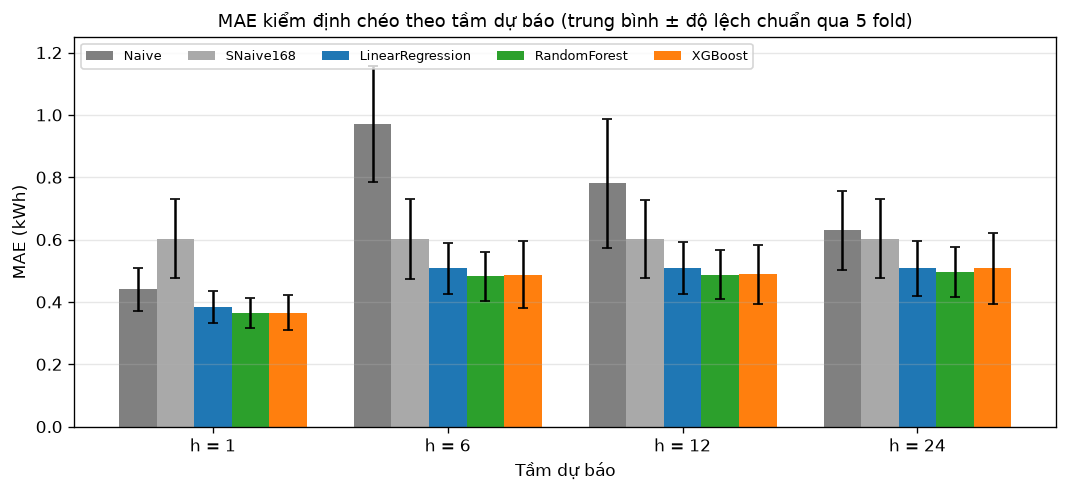

In [8]:
# HINH: mae_theo_h
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = {"Naive": "gray", "SNaive168": "darkgray", "LinearRegression": "tab:blue",
          "RandomForest": "tab:green", "XGBoost": "tab:orange"}
x = np.arange(len(HORIZONS))
width = 0.16
for i, m in enumerate(colors):
    s = summary[summary.model == m].set_index("h").loc[HORIZONS]
    ax.bar(x + (i - 2) * width, s["MAE_mean"], width, yerr=s["MAE_std"], capsize=3,
           color=colors[m], label=m)
ax.set_xticks(x, [f"h = {h}" for h in HORIZONS])
ax.set(xlabel="Tầm dự báo", ylabel="MAE (kWh)", title="MAE kiểm định chéo theo tầm dự báo (trung bình ± độ lệch chuẩn qua 5 fold)")
ax.grid(alpha=0.3, axis="y")
ax.legend(ncol=5, fontsize=8, loc="upper left")
ax.set_ylim(0, 1.25)
plt.tight_layout()
plt.show()

> **Nhận xét biểu đồ MAE theo tầm dự báo:**
> - Mô hình học máy giảm MAE $12,7$--$20,0\%$ so với mô hình cơ sở tốt nhất và tốt hơn ở **cả 5/5 fold** cho mọi cặp (mô hình, $h$) (bảng mục 5.2).
> - MAE của mô hình học máy tăng mạnh từ $h = 1$ ($0,37$--$0,38$) lên $h = 6$ ($\approx 0,48$--$0,51$) rồi gần như đi ngang đến $h = 24$. Ở $h = 1$ mô hình còn dựa được vào giá trị giờ vừa qua; từ $h = 6$ thông tin này gần như mất tác dụng và mô hình chủ yếu dựa vào chu kỳ ngày, tuần và đặc trưng lịch, nên sai số ổn định theo $h$.
> - Thanh sai số (độ lệch chuẩn qua fold) của mọi mô hình đều lớn, cho thấy sai số phụ thuộc nhiều vào giai đoạn kiểm định (mục kế tiếp).

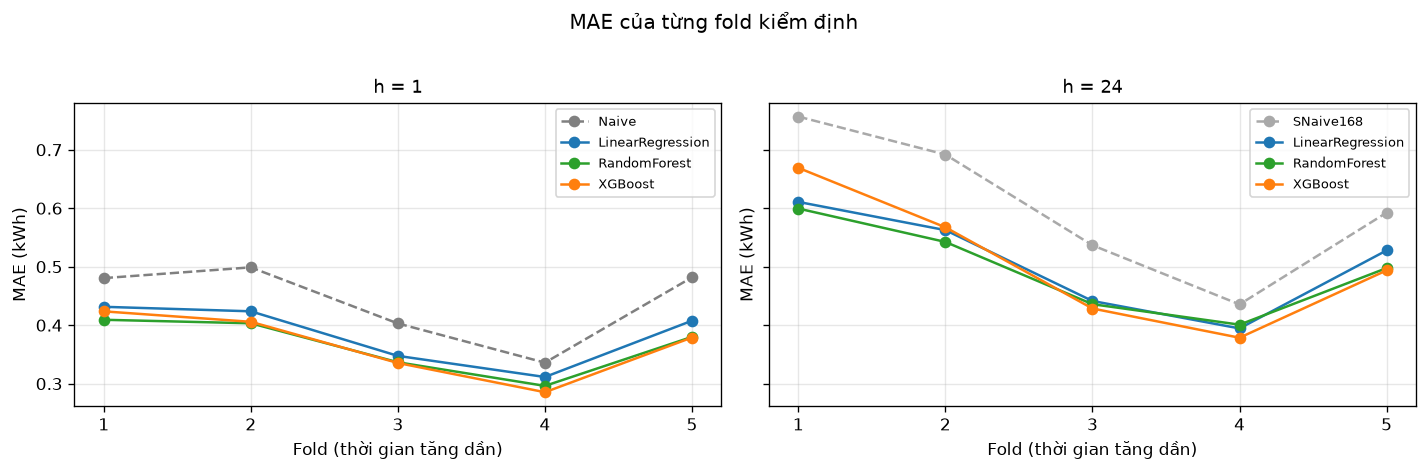

,Fold,Kiểm định từ,đến
0,1,2008-10-04,2009-01-02
1,2,2009-01-02,2009-04-03
2,3,2009-04-03,2009-07-04
3,4,2009-07-04,2009-10-02
4,5,2009-10-03,2009-12-31


In [9]:
# HINH: mae_theo_fold
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, h in zip(axes, (1, 24)):
    p = val[val.h == h].pivot(index="fold", columns="model", values="MAE")
    best_base = "Naive" if h == 1 else "SNaive168"
    for m, st in ((best_base, "--"), ("LinearRegression", "-"), ("RandomForest", "-"), ("XGBoost", "-")):
        ax.plot(p.index, p[m], st, marker="o", label=m, color=colors.get(m))
    ax.set(title=f"h = {h}", xlabel="Fold (thời gian tăng dần)", ylabel="MAE (kWh)", xticks=p.index)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("MAE của từng fold kiểm định", y=1.02)
plt.tight_layout()
plt.show()
fold_periods = pd.DataFrame([{"Fold": k, "Kiểm định từ": tables[1][1].iloc[va]["target_time"].min().date(),
                              "đến": tables[1][1].iloc[va]["target_time"].max().date()}
                             for k, (tr, va) in enumerate(all_folds[1], 1)])
fold_periods

> **Nhận xét MAE theo từng fold:**
> - Thứ hạng mô hình gần như giữ nguyên ở mọi fold: ba mô hình học máy luôn thấp hơn mô hình cơ sở tốt nhất, Linear Regression thường cao hơn hai mô hình cây.
> - Mức sai số thay đổi theo mùa của phần kiểm định: fold 4 (07--10/2009, có tháng 8 tiêu thụ thấp) có MAE thấp nhất, fold 1 và 2 (mùa đông, tiêu thụ cao) có MAE cao nhất. Vì vậy độ lệch chuẩn giữa các fold chủ yếu phản ánh mức tiêu thụ của từng giai đoạn, không phải mô hình thiếu ổn định.
> - Đây cũng là lý do nhóm báo cáo trung bình $\pm$ độ lệch chuẩn qua 5 fold thay vì kết quả của một lần chia.

## 6. Sai số trên tập huấn luyện và tập kiểm định

Sai số huấn luyện là sai số **trong mẫu** (mô hình dự báo lại chính dữ liệu đã học). Chênh lệch lớn giữa hai sai số là dấu hiệu quá khớp; cả hai cùng cao là dấu hiệu chưa khớp.

In [10]:
tv = (scores[scores.model.isin(ML_NAMES)].groupby(["h", "model", "set"])["MAE"].mean()
      .unstack("set").rename(columns={"train": "MAE huấn luyện", "val": "MAE kiểm định"}))
tv["Kiểm định / Huấn luyện"] = tv["MAE kiểm định"] / tv["MAE huấn luyện"]
tv.to_csv(RESULTS_DIR / "cv_train_vs_val.csv")
tv.round(3)

set                  MAE huấn luyện  MAE kiểm định  Kiểm định / Huấn luyện
h  model                                                                  
1  LinearRegression           0.409          0.384                   0.939
   RandomForest               0.241          0.365                   1.513
   XGBoost                    0.265          0.366                   1.381
6  LinearRegression           0.551          0.508                   0.923
   RandomForest               0.304          0.482                   1.584
   XGBoost                    0.334          0.488                   1.459
12 LinearRegression           0.551          0.509                   0.925
   RandomForest               0.308          0.488                   1.586
   XGBoost                    0.338          0.488                   1.447
24 LinearRegression           0.549          0.507                   0.924
   RandomForest               0.311          0.495                   1.592
   XGBoost                    0.339          0.507                   1.496

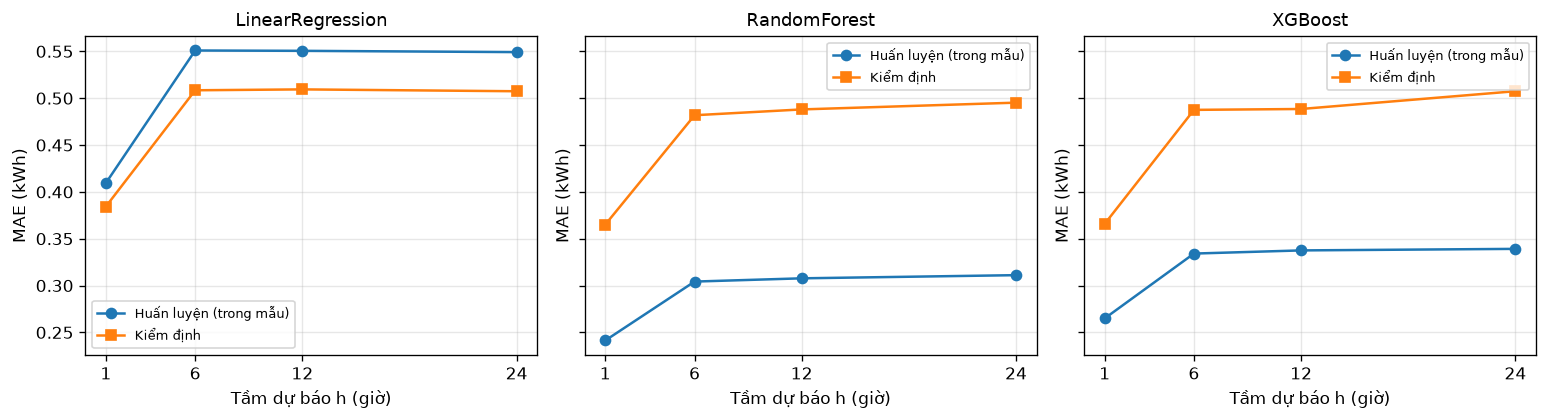

In [11]:
# HINH: train_val
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, ML_NAMES):
    d = tv.xs(m, level="model")
    ax.plot(d.index, d["MAE huấn luyện"], "o-", label="Huấn luyện (trong mẫu)")
    ax.plot(d.index, d["MAE kiểm định"], "s-", label="Kiểm định")
    ax.set(title=m, xlabel="Tầm dự báo h (giờ)", ylabel="MAE (kWh)", xticks=HORIZONS)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

> **Nhận xét sai số huấn luyện -- kiểm định:**
> - **Random Forest và XGBoost có khoảng cách lớn giữa hai sai số:** MAE huấn luyện chỉ $0,24$--$0,34$ kWh trong khi MAE kiểm định là $0,37$--$0,50$ kWh (gấp $1,4$--$1,6$ lần). Cần đọc con số này thận trọng: sai số huấn luyện ở đây là sai số **trong mẫu**, và với mô hình cây (đặc biệt Random Forest, mỗi lá chỉ cần 5 mẫu) sai số trong mẫu luôn thấp theo cấu tạo. Vì vậy khoảng cách này mới là **dấu hiệu** quá khớp, chưa phải bằng chứng đầy đủ; Bài kiểm tra 3 sẽ kiểm chứng bằng đường cong học tập và đường cong kiểm định theo độ phức tạp của cây.
> - **Linear Regression không quá khớp nhưng có dấu hiệu chưa khớp:** sai số huấn luyện ($0,41$--$0,55$) cao hơn hẳn sai số huấn luyện của mô hình cây và xấp xỉ sai số kiểm định của chính nó. Mô hình tuyến tính không biểu diễn được tương tác giữa giờ, thứ, tháng và mức tiêu thụ gần đây.
> - Sai số huấn luyện của Linear Regression còn hơi lớn hơn sai số kiểm định, vì phần huấn luyện gồm cả các mùa đông 2006--2008 tiêu thụ cao, còn các fold kiểm định 3--4 rơi vào mùa hè tiêu thụ thấp (xem bảng theo fold bên dưới).

In [12]:
# Theo từng fold với h = 1: kiểm tra chênh lệch huấn luyện - kiểm định có ổn định không
scores[(scores.h == 1) & scores.model.isin(ML_NAMES)].pivot_table(
    index="fold", columns=["model", "set"], values="MAE").round(3)

model LinearRegression        RandomForest        XGBoost       
set              train    val        train    val   train    val
fold                                                            
1                0.413  0.431        0.244  0.409   0.250  0.424
2                0.413  0.424        0.243  0.403   0.261  0.406
3                0.415  0.348        0.244  0.337   0.271  0.335
4                0.408  0.311        0.240  0.296   0.272  0.285
5                0.399  0.408        0.235  0.380   0.271  0.379

> **Nhận xét theo fold ($h = 1$):** sai số huấn luyện của từng mô hình gần như không đổi qua các fold (Random Forest $\approx 0,24$, XGBoost $0,25$--$0,27$, Linear Regression $0,40$--$0,42$), còn sai số kiểm định dao động theo mùa ($0,28$--$0,43$). Khoảng cách huấn luyện -- kiểm định của hai mô hình cây xuất hiện ở **mọi** fold, nên đây là đặc điểm nhất quán của mô hình chứ không do một fold riêng lẻ.

## 7. Phân tích lỗi trên dự báo kiểm định

Phần này dùng dự báo của mọi mô hình trên phần kiểm định của cả 5 fold (10.000+ giờ, từ 10/2008 đến 12/2009).

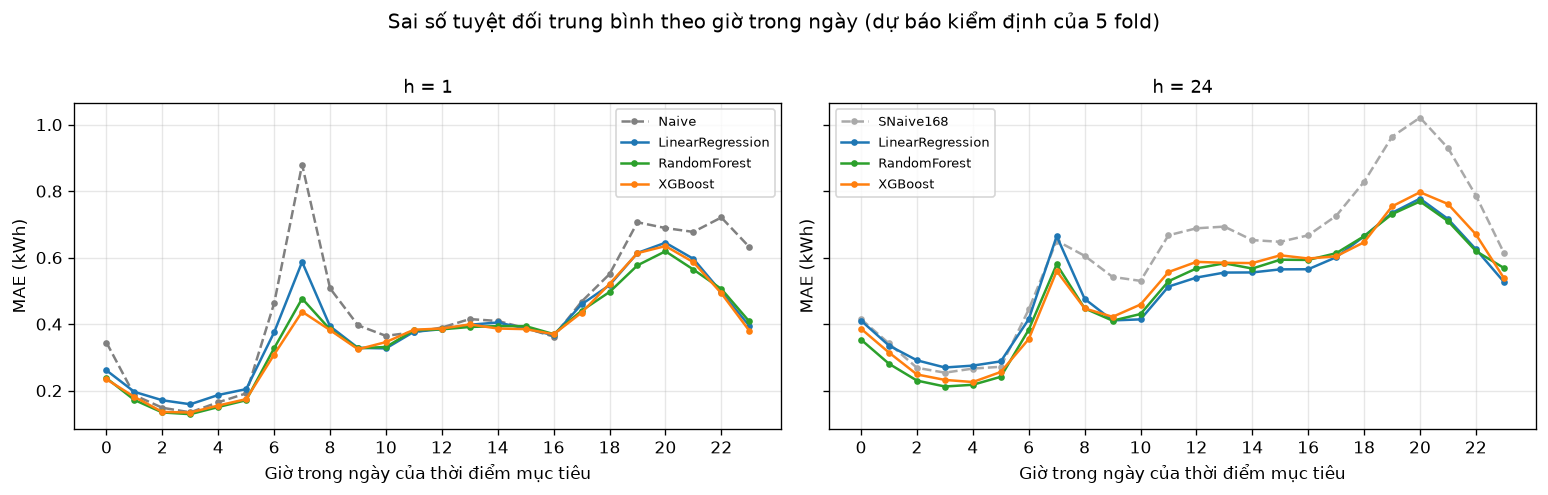

In [13]:
# HINH: mae_theo_gio
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, h in zip(axes, (1, 24)):
    o = oof[oof.h == h]
    best_base = "Naive" if h == 1 else "SNaive168"
    for m, st in ((best_base, "--"), ("LinearRegression", "-"), ("RandomForest", "-"), ("XGBoost", "-")):
        err = (o[m] - o["target"]).abs().groupby(o["target_time"].dt.hour).mean()
        ax.plot(err.index, err.values, st, marker=".", label=m, color=colors.get(m))
    ax.set(title=f"h = {h}", xlabel="Giờ trong ngày của thời điểm mục tiêu", ylabel="MAE (kWh)", xticks=range(0, 24, 2))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("Sai số tuyệt đối trung bình theo giờ trong ngày (dự báo kiểm định của 5 fold)", y=1.02)
plt.tight_layout()
plt.show()

> **Nhận xét sai số theo giờ trong ngày:**
> - Sai số nhỏ nhất vào ban đêm (3 giờ: $0,13$--$0,16$ kWh ở $h = 1$, $0,21$--$0,27$ kWh ở $h = 24$), khi hộ chỉ dùng tải nền.
> - **Đỉnh buổi tối 19--21 giờ là vùng khó nhất ở cả hai tầm dự báo:** ở $h = 1$ MAE của mô hình học máy là $0,56$--$0,65$ kWh; ở $h = 24$ là $0,71$--$0,80$ kWh. Đây là khung giờ có độ biến động lớn nhất (notebook 01, mục 5.2).
> - Mô hình học máy cải thiện mạnh nhất ở **đỉnh buổi sáng 7 giờ** với $h = 1$: Naive $0,88$ kWh, còn Random Forest $0,48$ và XGBoost $0,44$ kWh. Naive chỉ lặp lại giá trị 6 giờ sáng (thấp) nên luôn trễ một bước khi tiêu thụ tăng đột ngột, còn mô hình học máy biết từ đặc trưng `hour` rằng 7 giờ thường tăng.
> - Ở $h = 24$, mô hình học máy giảm sai số so với SNaive168 rõ nhất ở buổi tối (20 giờ: $1,02 \rightarrow 0,77$--$0,80$ kWh) nhưng gần như không tốt hơn ở 3--7 giờ sáng.

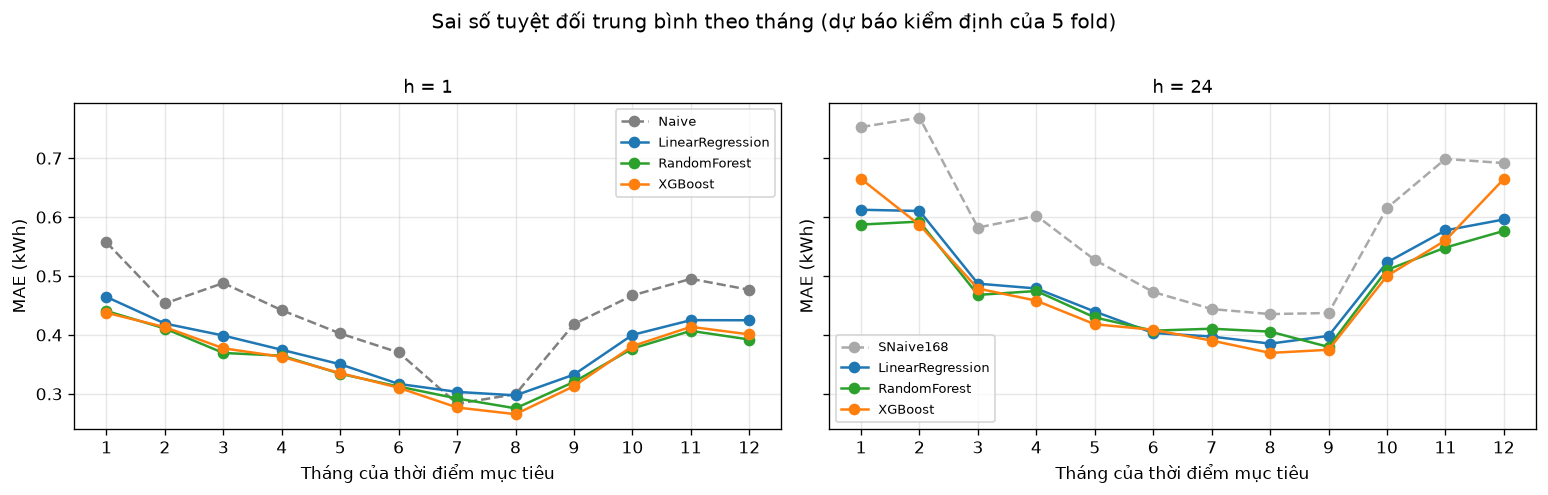

Điện năng trung bình theo tháng trong phần kiểm định (kWh): {1: 1.41, 2: 1.246, 3: 1.227, 4: 1.141, 5: 1.013, 6: 0.866, 7: 0.618, 8: 0.666, 9: 0.987, 10: 1.135, 11: 1.332, 12: 1.319}


In [14]:
# HINH: mae_theo_thang
o = oof.copy()
o["month"] = o["target_time"].dt.month
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, h in zip(axes, (1, 24)):
    d = o[o.h == h]
    best_base = "Naive" if h == 1 else "SNaive168"
    for m, st in ((best_base, "--"), ("LinearRegression", "-"), ("RandomForest", "-"), ("XGBoost", "-")):
        err = (d[m] - d["target"]).abs().groupby(d["month"]).mean()
        ax.plot(err.index, err.values, st, marker="o", label=m, color=colors.get(m))
    ax.set(title=f"h = {h}", xlabel="Tháng của thời điểm mục tiêu", ylabel="MAE (kWh)", xticks=range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("Sai số tuyệt đối trung bình theo tháng (dự báo kiểm định của 5 fold)", y=1.02)
plt.tight_layout()
plt.show()
month_target = o[o.h == 1].groupby("month")["target"].mean().round(3)
print("Điện năng trung bình theo tháng trong phần kiểm định (kWh):", month_target.to_dict())

> **Nhận xét sai số theo tháng:**
> - Sai số đi theo mức tiêu thụ: cao nhất vào mùa đông (tháng 1 và 12, điện năng trung bình $\approx 1,3$--$1,4$ kWh), thấp nhất vào tháng 7--8 ($\approx 0,6$--$0,7$ kWh). Đây là lý do MAE khác nhau nhiều giữa các fold.
> - Ở $h = 1$, **tháng 7 là tháng duy nhất mô hình học máy không tốt hơn Naive rõ rệt** (Naive $0,283$; XGBoost $0,277$; Random Forest $0,292$; Linear Regression $0,303$ kWh): khi tiêu thụ thấp và đều, giá trị giờ vừa qua đã là dự báo tốt.
> - Ở $h = 24$, XGBoost có MAE tháng 1 và tháng 12 (cùng $0,665$) cao hơn hẳn Random Forest ($0,587$; $0,577$), góp phần làm độ lệch chuẩn giữa các fold của XGBoost lớn hơn ($0,115$ so với $0,080$).

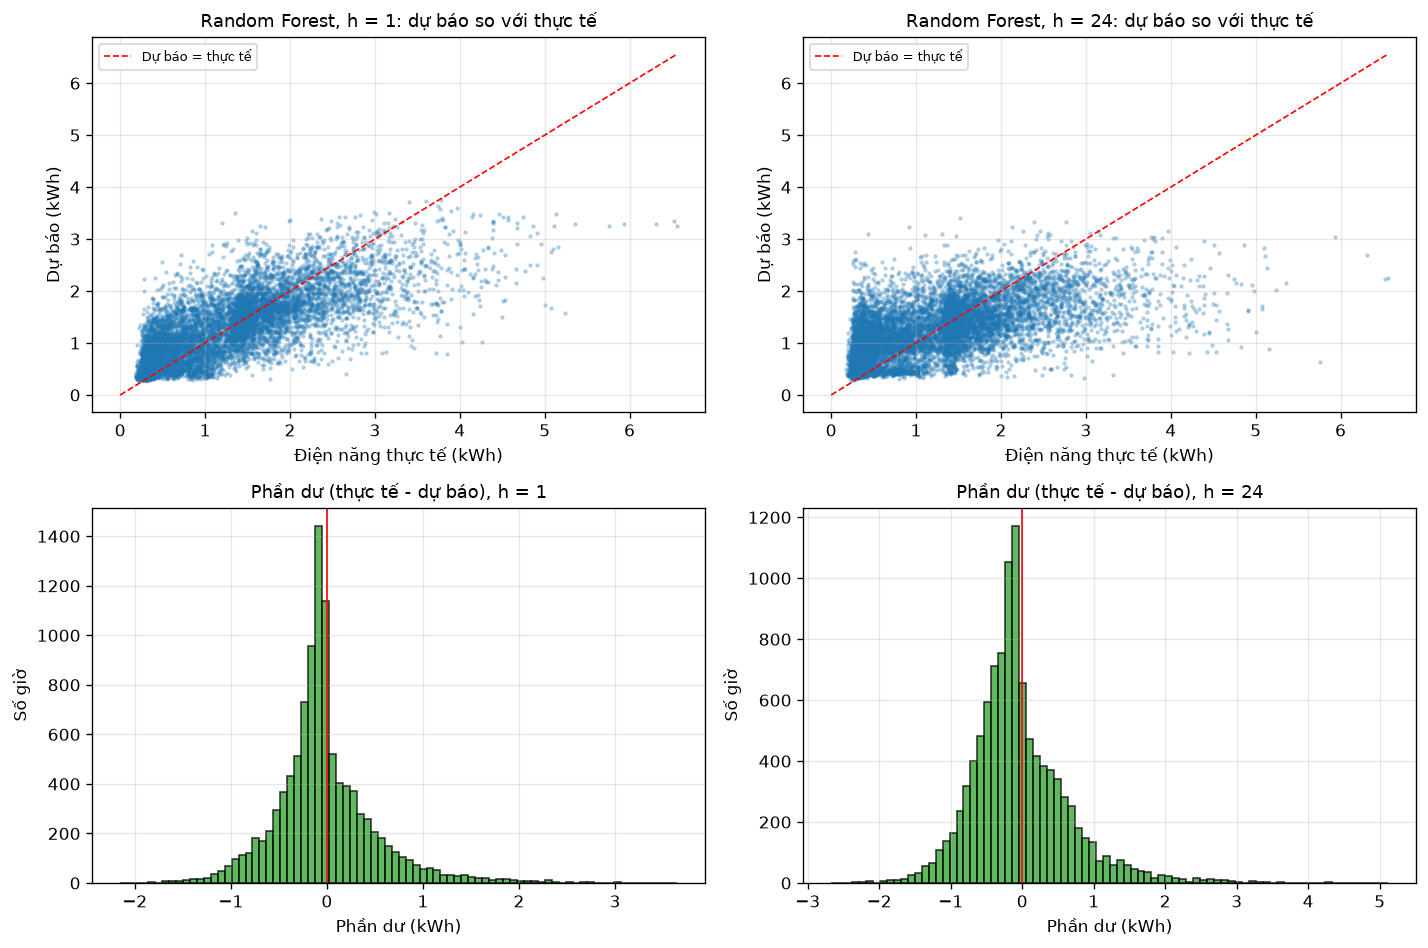

h = 1: trung bình phần dư -0.022 kWh | trung vị -0.074 | độ lệch (skew) 1.09
h = 24: trung bình phần dư -0.041 kWh | trung vị -0.128 | độ lệch (skew) 1.13


In [15]:
# HINH: phan_du
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, h in enumerate((1, 24)):
    d = oof[oof.h == h]
    resid = d["target"] - d["RandomForest"]
    ax = axes[0, col]
    ax.scatter(d["target"], d["RandomForest"], s=3, alpha=0.25)
    lim = [0, d["target"].max()]
    ax.plot(lim, lim, "r--", lw=1, label="Dự báo = thực tế")
    ax.set(title=f"Random Forest, h = {h}: dự báo so với thực tế", xlabel="Điện năng thực tế (kWh)", ylabel="Dự báo (kWh)")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    ax = axes[1, col]
    ax.hist(resid, bins=80, color="tab:green", alpha=0.75, edgecolor="black")
    ax.axvline(0, color="red", lw=1)
    ax.set(title=f"Phần dư (thực tế - dự báo), h = {h}", xlabel="Phần dư (kWh)", ylabel="Số giờ")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for h in (1, 24):
    d = oof[oof.h == h]
    r = d["target"] - d["RandomForest"]
    print(f"h = {h}: trung bình phần dư {r.mean():+.3f} kWh | trung vị {r.median():+.3f} | độ lệch (skew) {r.skew():.2f}")

> **Nhận xét phần dư (Random Forest):**
> - Trên biểu đồ dự báo -- thực tế, các điểm nằm dưới đường chéo ở vùng điện năng cao: mô hình **dự báo thấp các giờ đỉnh**. Ở $h = 24$ đám điểm dẹt hơn, tức dự báo bị "kéo" về giá trị trung bình nhiều hơn.
> - Phân bố phần dư lệch phải (skew $1,09$ ở $h = 1$, $1,13$ ở $h = 24$): phần lớn giờ có phần dư âm nhỏ (trung vị $-0,074$ và $-0,128$ kWh, tức dự báo hơi cao ở các giờ tải nền), xen với một số ít giờ có phần dư dương rất lớn (đỉnh bị dự báo thấp).
> - Trung bình phần dư gần 0 ($-0,022$ và $-0,041$ kWh), nên mô hình gần như không lệch hệ thống về tổng thể; sai số chủ yếu đến từ việc không đoán được thời điểm và độ lớn của đỉnh.

In [16]:
# Lỗi tập trung ở đâu: giờ tiêu thụ cao và giờ có sai số lớn nhất
rows = []
for h in (1, 24):
    d = oof[oof.h == h]
    q95, q10 = d["target"].quantile(0.95), d["target"].quantile(0.10)
    for m in ML_NAMES:
        err = d[m] - d["target"]
        abs_err = err.abs()
        top10 = abs_err >= abs_err.quantile(0.90)
        rows.append({"h": h, "Mô hình": m,
                     "Sai lệch TB ở 5% giờ cao nhất (kWh)": err[d["target"] >= q95].mean(),
                     "Sai lệch TB ở 10% giờ thấp nhất (kWh)": err[d["target"] <= q10].mean(),
                     "Tỷ trọng sai số của 10% giờ sai nhiều nhất (%)": 100 * abs_err[top10].sum() / abs_err.sum()})
peaks = pd.DataFrame(rows)
peaks.to_csv(RESULTS_DIR / "cv_error_concentration.csv", index=False)
print(f"Ngưỡng 5% giờ cao nhất (h = 1): {oof[oof.h == 1]['target'].quantile(0.95):.2f} kWh")
peaks.round(3)

Ngưỡng 5% giờ cao nhất (h = 1): 2.81 kWh


,h,Mô hình,Sai lệch TB ở 5% giờ cao nhất (kWh),Sai lệch TB ở 10% giờ thấp nhất (kWh),Tỷ trọng sai số của 10% giờ sai nhiều nhất (%)
0,1,LinearRegression,-1.112,0.214,33.154
1,1,RandomForest,-1.148,0.201,34.468
2,1,XGBoost,-1.061,0.189,34.361
3,24,LinearRegression,-1.626,0.425,30.560
4,24,RandomForest,-1.603,0.438,31.283
5,24,XGBoost,-1.436,0.440,31.608


> **Nhận xét lỗi tập trung:**
> - Ở 5% giờ tiêu thụ cao nhất (từ $2,81$ kWh trở lên), mọi mô hình học máy dự báo thấp trung bình $1,06$--$1,15$ kWh với $h = 1$ và $1,44$--$1,63$ kWh với $h = 24$.
> - Ngược lại, ở 10% giờ tiêu thụ thấp nhất, mô hình dự báo cao khoảng $0,19$--$0,21$ kWh ($h = 1$) và $0,43$--$0,44$ kWh ($h = 24$).
> - 10% số giờ có sai số lớn nhất chiếm $30,6$--$34,5\%$ tổng sai số tuyệt đối. Đây là hạn chế cố hữu của dự báo một giá trị: đỉnh tiêu thụ phụ thuộc hành vi khó đoán (bật nhiều thiết bị cùng lúc), nên mô hình tối ưu sai số trung bình sẽ có xu hướng dự báo về giữa.

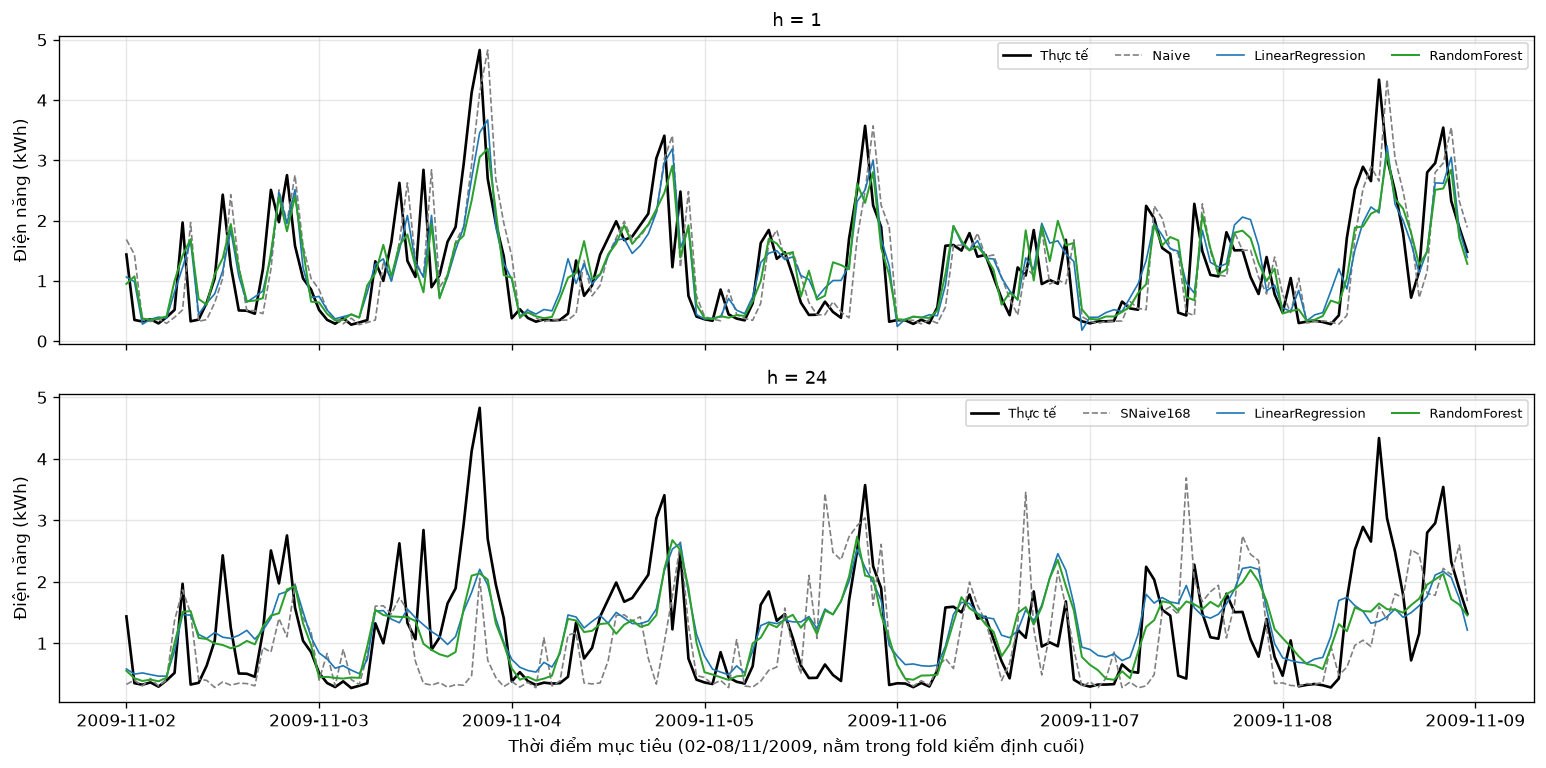

In [17]:
# HINH: tuan_vi_du
week = slice("2009-11-02", "2009-11-08")
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for ax, h in zip(axes, (1, 24)):
    d = oof[oof.h == h].copy()
    d = d.set_index("target_time").loc[week]           # vẽ theo thời điểm mục tiêu
    best_base = "Naive" if h == 1 else "SNaive168"
    ax.plot(d.index, d["target"], color="black", lw=1.6, label="Thực tế")
    ax.plot(d.index, d[best_base], "--", color="gray", lw=1, label=best_base)
    ax.plot(d.index, d["LinearRegression"], color="tab:blue", lw=1, label="LinearRegression")
    ax.plot(d.index, d["RandomForest"], color="tab:green", lw=1.2, label="RandomForest")
    ax.set(title=f"h = {h}", ylabel="Điện năng (kWh)")
    ax.grid(alpha=0.3)
    ax.legend(ncol=4, fontsize=8)
axes[1].set_xlabel("Thời điểm mục tiêu (02-08/11/2009, nằm trong fold kiểm định cuối)")
plt.tight_layout()
plt.show()

> **Nhận xét tuần ví dụ (02--08/11/2009):**
> - Với $h = 1$, các mô hình bám sát đường thực tế nhưng **trễ khoảng một giờ** ở các lần tăng đột ngột, và không đạt tới đỉnh $4,8$ kWh tối 03/11 (Random Forest chỉ khoảng $3,2$ kWh).
> - Với $h = 24$, dự báo của Linear Regression và Random Forest mượt hơn hẳn: chúng tái hiện được nhịp tăng buổi tối hằng ngày nhưng gần như bỏ qua các đỉnh riêng lẻ. SNaive168 sao chép nguyên tuần trước nên có những đỉnh "giả" (ví dụ ngày 05/11) không xảy ra trong tuần này.

## 8. Đặc trưng ảnh hưởng nhiều đến dự báo

Dùng **permutation importance** trên phần kiểm định của fold cuối: hoán vị ngẫu nhiên một đặc trưng và đo MAE tăng thêm bao nhiêu (5 lần lặp). Cách này áp dụng được cho cả ba mô hình và đo trên dữ liệu mô hình chưa thấy.

In [18]:
imp_rows = []
for h in (1, 24):
    for m in ML_NAMES:
        model, val_last = all_fitted[h][m]
        r = permutation_importance(model, val_last[FEATURES], val_last["target"], n_repeats=5,
                                   scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
        imp_rows += [{"h": h, "model": m, "feature": f, "MAE tăng (kWh)": v}
                     for f, v in zip(FEATURES, r.importances_mean)]
importance = pd.DataFrame(imp_rows)
importance.to_csv(RESULTS_DIR / "cv_permutation_importance.csv", index=False)
importance.pivot_table(index="feature", columns=["h", "model"], values="MAE tăng (kWh)").sort_values((1, "RandomForest"), ascending=False).head(10).round(3)

h                                 1                                     24  \
model               LinearRegression RandomForest XGBoost LinearRegression   
feature                                                                      
lag_0                          0.248        0.352   0.370            0.020   
hour                           0.068        0.047   0.083            0.126   
roll_mean_3                    0.157        0.019   0.028            0.089   
lag_1                          0.049        0.015   0.016            0.041   
same_hour_prev_week            0.006        0.007   0.002            0.047   
lag_167                        0.006        0.007   0.004           -0.001   
lag_5                          0.000        0.004   0.005           -0.000   
lag_11                         0.001        0.004   0.003            0.001   
lag_47                         0.004        0.004   0.002            0.013   
dayofweek                      0.004        0.003   0.008            0.011   

h                                         
model               RandomForest XGBoost  
feature                                   
lag_0                      0.009   0.007  
hour                       0.121   0.177  
roll_mean_3                0.010   0.002  
lag_1                      0.004   0.004  
same_hour_prev_week        0.036   0.018  
lag_167                    0.004   0.002  
lag_5                      0.002   0.002  
lag_11                     0.005   0.005  
lag_47                     0.010   0.009  
dayofweek                  0.011   0.028

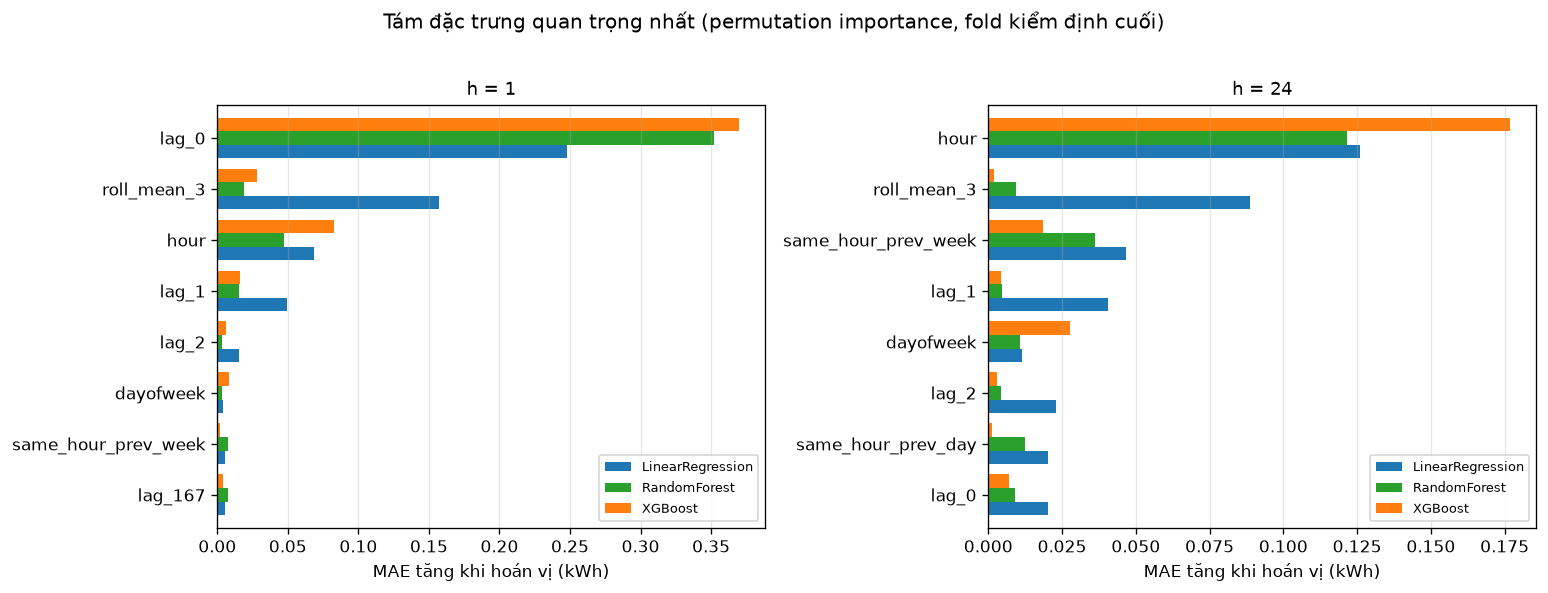

In [19]:
# HINH: tam_quan_trong
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, h in zip(axes, (1, 24)):
    p = importance[importance.h == h].pivot(index="feature", columns="model", values="MAE tăng (kWh)")
    p = p.loc[p.max(axis=1).sort_values(ascending=False).index[:8]][::-1]
    p[ML_NAMES].plot.barh(ax=ax, color=[colors[m] for m in ML_NAMES], width=0.8)
    ax.set(title=f"h = {h}", xlabel="MAE tăng khi hoán vị (kWh)", ylabel="")
    ax.grid(alpha=0.3, axis="x")
    ax.legend(fontsize=8, loc="lower right")
plt.suptitle("Tám đặc trưng quan trọng nhất (permutation importance, fold kiểm định cuối)", y=1.02)
plt.tight_layout()
plt.show()

> **Nhận xét đặc trưng quan trọng:**
> - **$h = 1$:** thông tin về vài giờ vừa qua áp đảo. Với hai mô hình cây, `lag_0` (điện năng giờ vừa qua) làm MAE tăng $0,35$--$0,37$ kWh khi bị hoán vị; Linear Regression chia tầm quan trọng này giữa `lag_0` ($0,25$) và `roll_mean_3` ($0,16$), vì trung bình 3 giờ gần nhất chứa chính $y_t$. Tiếp theo là `hour` ($0,05$--$0,08$). Kết quả khớp với tự tương quan bậc 1 cao ($0,719$) ở notebook 01.
> - **$h = 24$:** `hour` trở thành quan trọng nhất ($0,12$--$0,18$ kWh), tiếp theo là `same_hour_prev_week` ($0,02$--$0,05$), `dayofweek` (mô hình cây) và `roll_mean_3` (Linear Regression). Ở tầm dự báo này mô hình chủ yếu học **hồ sơ tiêu thụ theo giờ trong ngày và thứ trong tuần**, cộng với giá trị cùng giờ tuần trước.
> - Lưu ý diễn giải: các đặc trưng tương quan với nhau chia sẻ tầm quan trọng. Ví dụ ở $h = 24$, `lag_0` và `same_hour_prev_day` là **cùng một cột** $y_t$, nên tầm quan trọng của từng cột là nhỏ hơn tầm quan trọng thực của thông tin đó.

## 9. Hàm thao tác nhanh khi vấn đáp
Hàm `thu_nhanh` chạy lại kiểm định chéo cho **một** mô hình ở **một** tầm dự báo, với siêu tham số tùy chọn, và in thêm chỉ số $R^2$ (ví dụ về cách bổ sung một chỉ số đánh giá). Ví dụ:
- đổi siêu tham số: `thu_nhanh("RandomForest", 1, min_samples_leaf=20)`;
- thay thuật toán: sửa `MODELS` hoặc truyền tên khác trong `src/models.py`.

In [20]:
def thu_nhanh(model_name="XGBoost", h=1, **params):
    df, train, _ = tables[h]
    make = MODELS[model_name]
    one = {model_name: lambda cols: make(cols, **params) if params else make(cols)}
    sc, pred, _ = run_cv(train, FEATURES, all_folds[h], models=one)
    v = sc[(sc.model == model_name) & (sc.set == "val")]
    r2 = [r2_score(pred.loc[pred.fold == k, "target"], pred.loc[pred.fold == k, model_name]) for k in v.fold]
    print(f"{model_name} {params or '(mặc định)'} | h = {h}")
    print(f"  MAE  = {v.MAE.mean():.3f} ± {v.MAE.std():.3f} kWh")
    print(f"  RMSE = {v.RMSE.mean():.3f} ± {v.RMSE.std():.3f} kWh")
    print(f"  MAPE = {v.MAPE.mean():.1f} ± {v.MAPE.std():.1f} %")
    print(f"  R2   = {np.mean(r2):.3f} ± {np.std(r2, ddof=1):.3f}")

thu_nhanh("RandomForest", 1, min_samples_leaf=20)

RandomForest {'min_samples_leaf': 20} | h = 1
  MAE  = 0.367 ± 0.049 kWh
  RMSE = 0.529 ± 0.075 kWh
  MAPE = 44.5 ± 4.0 %
  R2   = 0.593 ± 0.041


> **Ví dụ thao tác:** tăng `min_samples_leaf` của Random Forest từ 5 lên 20 cho MAE kiểm định $0,367 \pm 0,049$ kWh, gần như không đổi so với cấu hình mặc định ($0,365 \pm 0,048$). Hàm cũng in $R^2 \approx 0,59$: mô hình giải thích được khoảng 59% phương sai của điện năng giờ kế tiếp.

## 10. Tổng kết

**Kết quả chính của Bài kiểm tra 2 (kiểm định chéo trên tập huấn luyện):**
1. Cả ba mô hình học máy (Linear Regression, Random Forest, XGBoost) vượt mọi mô hình cơ sở ở cả bốn tầm dự báo, ở 5/5 fold, giảm MAE $12,7$--$20,0\%$ so với mô hình cơ sở tốt nhất (Naive ở $h = 1$, SNaive168 ở $h \ge 6$).
2. Random Forest có MAE thấp nhất hoặc ngang thấp nhất ở mọi tầm dự báo, tốt hơn Linear Regression $0,01$--$0,03$ kWh; XGBoost ngang Random Forest ở $h \le 12$ nhưng ở $h = 24$ chỉ ngang Linear Regression.
3. Hai mô hình cây có MAE kiểm định gấp $1,4$--$1,6$ lần MAE huấn luyện trong mẫu, là dấu hiệu quá khớp cần kiểm chứng thêm; Linear Regression có dấu hiệu chưa khớp.
4. Sai số tập trung ở đỉnh buổi tối 19--21 giờ, vào mùa đông và ở các giờ tiêu thụ đột biến; mô hình dự báo thấp các đỉnh và dự báo cao các giờ tải nền.
5. Đặc trưng quan trọng nhất là điện năng giờ vừa qua ($h = 1$) và giờ trong ngày ($h = 24$).

**Chuyển sang Bài kiểm tra 3:** kiểm chứng quá khớp bằng đường cong học tập và đường cong kiểm định, tối ưu siêu tham số trên cùng các fold, thử cải tiến đặc trưng (ví dụ ngày lễ, giá trị trễ của các nhóm công tơ phụ), thử phương pháp tổ hợp, sau đó đánh giá mô hình cuối **một lần** trên tập kiểm tra năm 2010.